In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings for cleaner tables
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

# Load dataset
df = pd.read_csv("../data/Churn_Modelling.csv")

print(f"Dataset shape: {df.shape[0]:,} rows, {df.shape[1]} columns")
display(df.head())

C:\Users\OWEN\AppData\Local\Temp\ipykernel_37244\513514670.py:1: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


Dataset shape: 10,000 rows, 14 columns


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [2]:
print("--- Missing Values ---")
print(df.isnull().sum()[df.isnull().sum() > 0])  # Prints nothing if clean

print("\n--- Data Types ---")
print(df.dtypes)

churn_rate = df["Exited"].value_counts(normalize=True) * 100
print(f"\nRetained (0): {churn_rate[0]:.2f}% | Churned (1): {churn_rate[1]:.2f}%")

--- Missing Values ---
Series([], dtype: int64)

--- Data Types ---
RowNumber            int64
CustomerId           int64
Surname             object
CreditScore          int64
Geography           object
Gender              object
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object

Retained (0): 79.63% | Churned (1): 20.37%


C:\Users\OWEN\AppData\Local\Temp\ipykernel_37244\3465870192.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="Geography", y="Exited", ax=axes[0, 0], palette="Blues_d")
C:\Users\OWEN\AppData\Local\Temp\ipykernel_37244\3465870192.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="NumOfProducts", y="Exited", ax=axes[0, 1], palette="Oranges_d")
C:\Users\OWEN\AppData\Local\Temp\ipykernel_37244\3465870192.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="IsActiveMember", y="Exited", ax=axes[1, 0], palette=

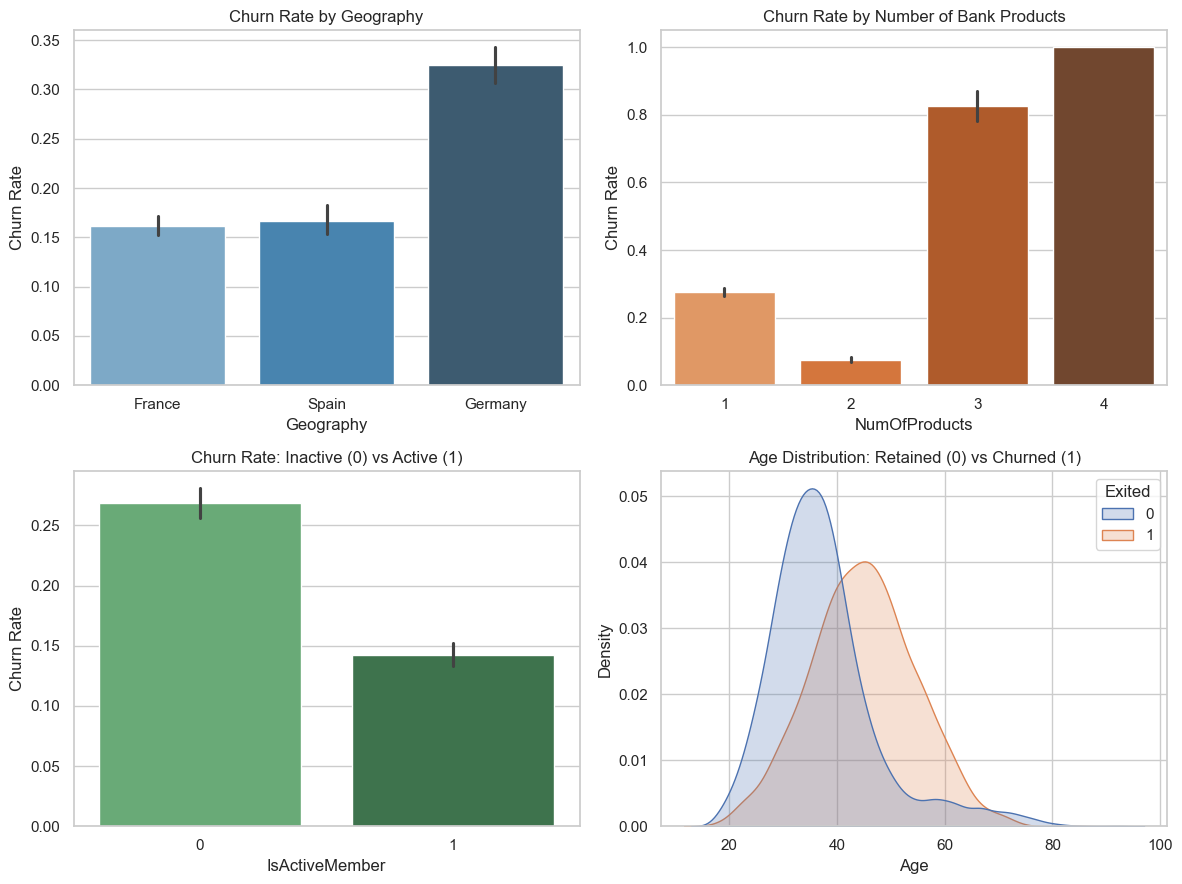

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# 1. Churn by Geography
sns.barplot(data=df, x="Geography", y="Exited", ax=axes[0, 0], palette="Blues_d")
axes[0, 0].set_title("Churn Rate by Geography")
axes[0, 0].set_ylabel("Churn Rate")

# 2. Churn by Number of Products
sns.barplot(data=df, x="NumOfProducts", y="Exited", ax=axes[0, 1], palette="Oranges_d")
axes[0, 1].set_title("Churn Rate by Number of Bank Products")
axes[0, 1].set_ylabel("Churn Rate")

# 3. Churn by Active Membership
sns.barplot(data=df, x="IsActiveMember", y="Exited", ax=axes[1, 0], palette="Greens_d")
axes[1, 0].set_title("Churn Rate: Inactive (0) vs Active (1)")
axes[1, 0].set_ylabel("Churn Rate")

# 4. Age Distribution by Churn Status
sns.kdeplot(data=df, x="Age", hue="Exited", fill=True, common_norm=False, ax=axes[1, 1])
axes[1, 1].set_title("Age Distribution: Retained (0) vs Churned (1)")

plt.tight_layout()
plt.show()

In [4]:
from sklearn.model_selection import train_test_split

def engineer_features(data: pd.DataFrame) -> pd.DataFrame:
    df_feat = data.copy()
    
    # Drop identifiers that cause overfitting
    drop_cols = ["RowNumber", "CustomerId", "Surname"]
    df_feat = df_feat.drop(columns=[c for c in drop_cols if c in df_feat.columns])
    
    # Banking domain features
    df_feat["Balance_to_Salary"] = df_feat["Balance"] / (df_feat["EstimatedSalary"] + 1)
    df_feat["Tenure_to_Age"] = df_feat["Tenure"] / df_feat["Age"]
    df_feat["Products_Per_Tenure"] = df_feat["NumOfProducts"] / (df_feat["Tenure"] + 1)
    df_feat["Zero_Balance_Flag"] = (df_feat["Balance"] == 0).astype(int)
    
    # One-hot encode Geography and Gender
    df_feat = pd.get_dummies(df_feat, columns=["Geography", "Gender"], drop_first=True, dtype=int)
    
    return df_feat

df_processed = engineer_features(df)

X = df_processed.drop(columns=["Exited"])
y = df_processed["Exited"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape:  {X_test.shape}")
print("Features:", list(X.columns))

Training features shape: (8000, 15)
Testing features shape:  (2000, 15)
Features: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Balance_to_Salary', 'Tenure_to_Age', 'Products_Per_Tenure', 'Zero_Balance_Flag', 'Geography_Germany', 'Geography_Spain', 'Gender_Male']


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, classification_report, f1_score

# 1. Baseline: Logistic Regression (requires feature scaling)
baseline_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", random_state=42, max_iter=1000)
)
baseline_model.fit(X_train, y_train)
base_probs = baseline_model.predict_proba(X_test)[:, 1]
base_preds = baseline_model.predict(X_test)

# 2. Challenger: LightGBM (handles raw scales & non-linear patterns like NumOfProducts=3,4)
lgbm_model = LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    num_leaves=31,
    class_weight="balanced",
    random_state=42,
    verbose=-1
)
lgbm_model.fit(X_train, y_train)
lgbm_probs = lgbm_model.predict_proba(X_test)[:, 1]
lgbm_preds = lgbm_model.predict(X_test)

print(f"Logistic Regression ROC-AUC: {roc_auc_score(y_test, base_probs):.4f} | F1: {f1_score(y_test, base_preds):.4f}")
print(f"LightGBM            ROC-AUC: {roc_auc_score(y_test, lgbm_probs):.4f} | F1: {f1_score(y_test, lgbm_preds):.4f}")
print("\n--- LightGBM Classification Report ---")
print(classification_report(y_test, lgbm_preds, target_names=["Retained (0)", "Churned (1)"]))

Logistic Regression ROC-AUC: 0.7748 | F1: 0.5030
LightGBM            ROC-AUC: 0.8615 | F1: 0.6176

--- LightGBM Classification Report ---
              precision    recall  f1-score   support

Retained (0)       0.92      0.85      0.89      1593
 Churned (1)       0.55      0.70      0.62       407

    accuracy                           0.82      2000
   macro avg       0.74      0.78      0.75      2000
weighted avg       0.84      0.82      0.83      2000



DEPRECATION: Loading egg at c:\python312\lib\site-packages\vboxapi-1.0-py3.12.egg is deprecated. pip 24.3 will enforce this behaviour change. A possible replacement is to use pip for package installation.. Discussion can be found at https://github.com/pypa/pip/issues/12330
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
contourpy 1.2.0 requires numpy<2.0,>=1.20, but you have numpy 2.5.5 which is incompatible.
matplotlib 3.8.3 requires numpy<2,>=1.21, but you have numpy 2.5.5 which is incompatible.

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



  Using cached shap-0.54.1-cp312-abi3-win_amd64.whl.metadata (23 kB)
  Using cached numpy-2.5.5-cp312-cp312-win_amd64.whl.metadata (6.6 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
INFO: pip is looking at multiple versions of pandas to determine which version is compatible with other requirements. This could take a while.
  Using cached pandas-3.1.1-cp312-cp312-win_amd64.whl.metadata (16 kB)
INFO: pip is looking at multiple versions of scikit-learn to determine which version is compatible with other requirements. This could take a while.
  Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.28.0-py3-none-any.whl.metadata (15 kB)
INFO: pip is looking at multiple versions of scipy to determine which version is compatible with other requirements. This could take a while.
  Using cached scipy-1.18.1-cp312-cp312-win_amd64.whl.metadata (61 kB)
Using cac

c:\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\OWEN\AppData\Roaming\Python\Python312\site-packages\shap\explainers\_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


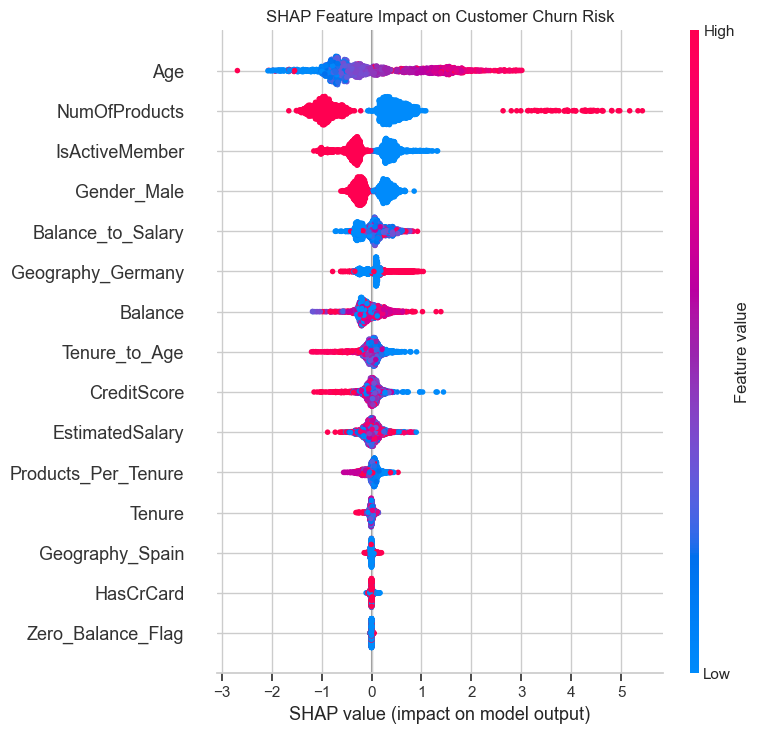

In [8]:
%pip install shap --user
import shap

# Compute SHAP values for LightGBM
explainer = shap.TreeExplainer(lgbm_model)
shap_values = explainer.shap_values(X_test)

# Handle binary SHAP output format across SHAP versions
if isinstance(shap_values, list):
    shap_vals_churn = shap_values[1]
else:
    shap_vals_churn = shap_values

# Summary beeswarm plot (save high-res image for your GitHub README!)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals_churn, X_test, show=False)
plt.title("SHAP Feature Impact on Customer Churn Risk")
plt.tight_layout()
plt.savefig("../models/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
import joblib

artifact = {
    "model": lgbm_model,
    "feature_names": list(X_train.columns)
}
joblib.dump(artifact, "../models/churn_lgbm_v1.joblib")
print("Saved model successfully to ../models/churn_lgbm_v1.joblib")

Saved model successfully to ../models/churn_lgbm_v1.joblib
